## Step 1 — Import packages and set a repeatable random seed

All packages are installed through `requirements.txt`. Reusing the same seed makes model comparisons more consistent.

In [89]:

from pathlib import Path
import copy, json, random
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import matplotlib.pyplot as plt
import mlflow
import joblib

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
ROOT = Path.cwd()
if not (ROOT / 'data' / 'housing.csv').exists():
    ROOT = ROOT.parent  # when notebook opened from a subfolder
(ROOT / 'results').mkdir(exist_ok=True)
print('Dataset:', ROOT / 'data' / 'housing.csv')

Dataset: c:\Users\helen\project\ds-october-2026-week2\ds-october-2026\data\housing.csv


In [90]:
df = pd.read_csv("housing.csv")
df.head(5)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## Step 2 — Load data and check missing values

`median_house_value` is the target. `ocean_proximity` is categorical; `total_bedrooms` has missing entries. Do **not** drop all rows just because a numerical value is missing.

In [91]:
df = pd.read_csv('housing.csv')
print('Shape:', df.shape)
print('Missing values by column:')
print(df.isnull().sum())
display(df.head())
print('Target:', 'median_house_value')

Shape: (20640, 10)
Missing values by column:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


Target: median_house_value


## Step 3 — Train / validation / test split (70% / 15% / 15%)

The test set is held back until the champion and challenger are selected. Splitting **before fitting** the imputers and scalers avoids data leakage.

In [92]:
X = df.drop(columns=['median_house_value'])
y = df['median_house_value']
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=.30, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=.50, random_state=SEED)
print('Train', len(X_train), 'Validation', len(X_val), 'Test', len(X_test))

Train 14448 Validation 3096 Test 3096


## Step 4 — Median imputation, numerical scaling, one-hot encoding

Fitting only on the **training** portion protects against leakage. Numeric features get `StandardScaler`; the categorical column gets `OneHotEncoder`. To stabilise training, target prices are divided by 100,000 and **predictions are converted back to dollars** for metrics.

In [93]:
numeric_cols = X_train.select_dtypes(include='number').columns.tolist()
categorical_cols = X_train.select_dtypes(exclude='number').columns.tolist()
preprocessor = ColumnTransformer([
    ('numeric', Pipeline([('imputer', SimpleImputer(strategy='median')),
                          ('scaler', StandardScaler())]), numeric_cols),
    ('categorical', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                              ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), categorical_cols)
], sparse_threshold=0)
Xtr = preprocessor.fit_transform(X_train).astype('float32')
Xva = preprocessor.transform(X_val).astype('float32')
Xte = preprocessor.transform(X_test).astype('float32')
ytr = (y_train.to_numpy(dtype='float32') / 100_000).reshape(-1,1)
yva = (y_val.to_numpy(dtype='float32') / 100_000).reshape(-1,1)
joblib.dump(preprocessor, ROOT / 'results' / 'preprocessor.joblib')
print('Transformed shapes:', Xtr.shape, Xva.shape, Xte.shape)
assert not np.isnan(Xtr).any()

2026/10/18 12:50:18 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID 'ec1775f266544da2804d53d6a6f0652c', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current sklearn workflow
2026/10/18 12:50:19 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/10/18 12:50:19 WARNING mlflow.sklearn: Model was missing function: predict. Not logging python_function flavor!
2026/10/18 12:50:26 WARNING mlflow.sklearn: Training metrics will not be recorded because training labels were not specified. To automatically record training metrics, provide training labels as inputs to the model traini

Transformed shapes: (14448, 13) (3096, 13) (3096, 13)


## Step 5 — Define THREE neural networks

For **regression**, the final layer has **1 neuron and no sigmoid/softmax activation**. The loss is **mean squared error (MSE)**. All hidden layers use ReLU.

Model 1: Basic MLP. Model 2: deeper MLP. Model 3: deep MLP with dropout and batch normalisation.

In [94]:
CONFIGS = [
    dict(name='Basic MLP', run_name='mlp-64x32-no-dropout', units=[64,32], dropout=0.0, batch_norm=False),
    dict(name='Deep MLP', run_name='dnn-128x64x32-no-dropout', units=[128,64,32], dropout=0.0, batch_norm=False),
    dict(name='Regularised MLP', run_name='dnn-128x64x32-dropout0.15-bn', units=[128,64,32], dropout=0.15, batch_norm=True),
]

def build_model(n_features, config):
    layers = []
    current = n_features
    for width in config['units']:
        layers.append(nn.Linear(current, width))
        if config['batch_norm']:
            layers.append(nn.BatchNorm1d(width))
        layers.append(nn.ReLU())
        if config['dropout'] > 0:
            layers.append(nn.Dropout(config['dropout']))
        current = width
    layers.append(nn.Linear(current, 1))  # regression: LINEAR output, no activation
    return nn.Sequential(*layers)

for cfg in CONFIGS:
    print(cfg['name'], build_model(Xtr.shape[1],cfg))

Basic MLP Sequential(
  (0): Linear(in_features=13, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=1, bias=True)
)
Deep MLP Sequential(
  (0): Linear(in_features=13, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=64, bias=True)
  (3): ReLU()
  (4): Linear(in_features=64, out_features=32, bias=True)
  (5): ReLU()
  (6): Linear(in_features=32, out_features=1, bias=True)
)
Regularised MLP Sequential(
  (0): Linear(in_features=13, out_features=128, bias=True)
  (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU()
  (3): Dropout(p=0.15, inplace=False)
  (4): Linear(in_features=128, out_features=64, bias=True)
  (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (6): ReLU()
  (7): Dropout(p=0.15, inplace=False)
  (8): Linear(in_features=64, 

## Step 6 — Train, validate, log EACH epoch to MLflow

For each model, log parameters, `train_loss` and `val_loss` every epoch, metrics **MAE/RMSE/R²**, a PNG loss plot, and the model checkpoint. Early stopping restores weights from the best validation epoch.

**Note:** Loss is MSE of prices divided by 100,000; RMSE/MAE are reported in **dollars**.

In [95]:
import mlflow
from mlflow.entities import ViewType
from mlflow.tracking import MlflowClient

mlflow.set_tracking_uri("sqlite:///mlflow.db")
client = MlflowClient()
experiments = client.search_experiments(view_type=ViewType.ALL)
for experiment in experiments:
    if experiment.name in {"California Housing Deep Learning", "housing"} and experiment.lifecycle_stage == "deleted":
        client.restore_experiment(experiment.experiment_id)

print("MLflow experiments are ready!")

MLflow experiments are ready!


In [96]:
import mlflow

# Set up MLflow using SQLite database
mlflow.set_tracking_uri("sqlite:///mlflow.db")

# Create or select experiment
mlflow.set_experiment("California Housing Deep Learning")

print("MLflow experiment is ready!")

train_loader = DataLoader(TensorDataset(torch.from_numpy(Xtr), torch.from_numpy(ytr)),
                          batch_size=256, shuffle=True)
MAX_EPOCHS, PATIENCE = 60, 9

def score(model, features, true_values):
    model.eval()
    with torch.no_grad():
        preds = model(torch.from_numpy(features)).numpy().flatten() * 100_000
    actual = np.asarray(true_values)
    return dict(mae=float(mean_absolute_error(actual,preds)),
                rmse=float(np.sqrt(mean_squared_error(actual,preds))),
                r2=float(r2_score(actual,preds)))

results, fitted_models, all_histories, run_ids = [], {}, {}, {}
for cfg in CONFIGS:
    torch.manual_seed(SEED)
    model = build_model(Xtr.shape[1],cfg)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.MSELoss()
    history, best_val, best_epoch, wait, best_weights = [], float('inf'), 0, 0, None
    with mlflow.start_run(run_name=cfg['run_name']) as run:
        run_ids[cfg['name']] = run.info.run_id
        mlflow.log_params({
            'architecture':cfg['name'], 'layers':len(cfg['units']),
            'units':'-'.join(map(str,cfg['units'])), 'activation':'ReLU',
            'optimiser':'Adam','learning_rate':0.001,'batch_size':256,
            'epochs':MAX_EPOCHS,'dropout':cfg['dropout'], 'batch_norm':cfg['batch_norm'],
            'output_units':1,'output_activation':'none','loss':'MSE','split':'70/15/15','seed':SEED
        })
        for epoch in range(1, MAX_EPOCHS+1):
            model.train()
            for xb,yb in train_loader:
                optimizer.zero_grad()
                loss = criterion(model(xb),yb)
                loss.backward()
                optimizer.step()
            model.eval()
            with torch.no_grad():
                tr_loss = criterion(model(torch.from_numpy(Xtr)), torch.from_numpy(ytr)).item()
                va_loss = criterion(model(torch.from_numpy(Xva)), torch.from_numpy(yva)).item()
            history.append({'epoch':epoch,'train_loss':tr_loss,'val_loss':va_loss})
            mlflow.log_metrics({'train_loss':tr_loss,'val_loss':va_loss},step=epoch)
            if va_loss < best_val - 1e-5:
                best_val,best_epoch,best_weights,wait = va_loss,epoch,copy.deepcopy(model.state_dict()),0
            else:
                wait += 1
            if wait >= PATIENCE:
                break
        model.load_state_dict(best_weights)
        val_metrics = score(model, Xva, y_val)
        mlflow.log_metrics({f'val_{key}':val for key,val in val_metrics.items()})
        mlflow.log_metric('best_epoch',best_epoch)
        safe = cfg['name'].lower().replace(' ','_')
        hdf = pd.DataFrame(history)
        hpath = ROOT / 'results' / f'loss_history_{safe}.csv'
        hdf.to_csv(hpath,index=False)
        fig, ax = plt.subplots(figsize=(8,4))
        ax.plot(hdf.epoch,hdf.train_loss,label='Training MSE')
        ax.plot(hdf.epoch,hdf.val_loss,label='Validation MSE')
        ax.set(xlabel='Epoch',ylabel='MSE (scaled target)',title=cfg['name'])
        ax.legend(); ax.grid(alpha=.3)
        fig.tight_layout()
        plot_file = ROOT / 'results' / f'loss_curve_{safe}.png'
        fig.savefig(plot_file,dpi=160); plt.close(fig)
        checkpoint = ROOT / 'results' / f'model_{safe}.pt'
        torch.save({'state_dict':model.state_dict(),'config':cfg,'input_features':Xtr.shape[1]}, checkpoint)
        mlflow.log_artifact(str(hpath), artifact_path='history')
        mlflow.log_artifact(str(plot_file), artifact_path='loss_curve')
        mlflow.log_artifact(str(checkpoint), artifact_path='model')
    fitted_models[cfg['name']]=model
    all_histories[cfg['name']]=hdf
    results.append({'model':cfg['name'],'run_name':cfg['run_name'], 'best_epoch':best_epoch,
                    **{f'val_{k}':v for k,v in val_metrics.items()}})
    print(cfg['name'],'best epoch',best_epoch,'validation RMSE $',round(val_metrics['rmse'],2))

MLflow experiment is ready!
Basic MLP best epoch 59 validation RMSE $ 56465.42
Deep MLP best epoch 43 validation RMSE $ 54617.26
Regularised MLP best epoch 60 validation RMSE $ 54005.29


## Step 7 — Compare and choose Champion / Challenger on **validation RMSE**

**Lower RMSE = better.** Do not use the test set for model selection.

In [97]:
ranking = pd.DataFrame(results).sort_values('val_rmse').reset_index(drop=True)
ranking['role'] = ['Champion','Challenger','Other']
display(ranking)
champion = ranking.loc[0,'model']
challenger = ranking.loc[1,'model']
print('CHAMPION:',champion,'| CHALLENGER:',challenger)

,model,run_name,best_epoch,val_mae,val_rmse,val_r2,role
0,Regularised MLP,dnn-128x64x32-dropout0.15-bn,60,35559.234656,54005.294114,0.776125,Champion
1,Deep MLP,dnn-128x64x32-no-dropout,43,36923.715948,54617.259887,0.771022,Challenger
2,Basic MLP,mlp-64x32-no-dropout,59,38505.099687,56465.424179,0.755264,Other


CHAMPION: Regularised MLP | CHALLENGER: Deep MLP


## Step 8 — Final held-out test results for the two selected models

The test set is only evaluated **after** the validation-based decision. These test results estimate how well the models might generalise to unseen examples.

In [98]:
for name in [champion, challenger]:
    scores = score(fitted_models[name], Xte, y_test)
    print(name, 'test metrics (USD):', {k:round(v,3) for k,v in scores.items()})
    for k,v in scores.items():
        ranking.loc[ranking['model']==name, 'test_'+k] = v
    with mlflow.start_run(run_id=run_ids[name]):
        mlflow.log_metrics({'test_'+key:value for key,value in scores.items()})
        mlflow.set_tag('model_role', 'Champion' if name == champion else 'Challenger')
ranking.to_csv(ROOT / 'results' / 'model_comparison.csv',index=False)
display(ranking)
with mlflow.start_run(run_id=run_ids[ranking.loc[2, 'model']]):
    mlflow.set_tag('model_role', 'Other')

summary = {'champion': champion, 'challenger': challenger, 'selection_metric': 'validation RMSE'}
(ROOT / 'results' / 'summary_from_notebook.json').write_text(json.dumps(summary, indent=2))

with mlflow.start_run(run_id=run_ids[champion]):
    mlflow.log_artifact(str(ROOT / 'results' / 'model_comparison.csv'), artifact_path='comparison')


Regularised MLP test metrics (USD): {'mae': 34181.787, 'rmse': 50336.699, 'r2': 0.808}
Deep MLP test metrics (USD): {'mae': 35258.17, 'rmse': 50885.239, 'r2': 0.804}


,model,run_name,best_epoch,val_mae,val_rmse,val_r2,role,test_mae,test_rmse,test_r2
0,Regularised MLP,dnn-128x64x32-dropout0.15-bn,60,35559.234656,54005.294114,0.776125,Champion,34181.786928,50336.698959,0.808382
1,Deep MLP,dnn-128x64x32-no-dropout,43,36923.715948,54617.259887,0.771022,Challenger,35258.169825,50885.239150,0.804183
2,Basic MLP,mlp-64x32-no-dropout,59,38505.099687,56465.424179,0.755264,Other,NaN,NaN,NaN


## Step 9 — Read training/validation curves and check overfitting

Overfitting signal: training MSE continues downward **while validation MSE turns upwards consistently**. One noisy validation epoch does not prove overfitting. Use early stopping and compare validation scores. No result should be described as overfitting without inspecting the plots.

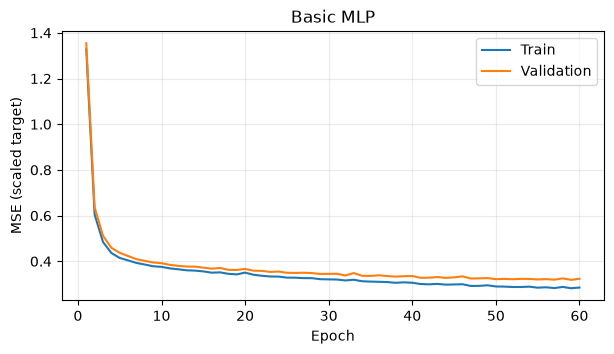

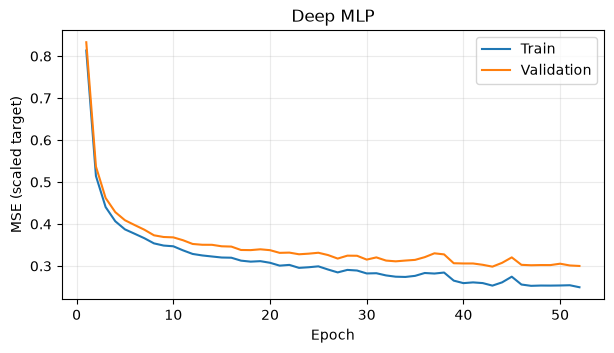

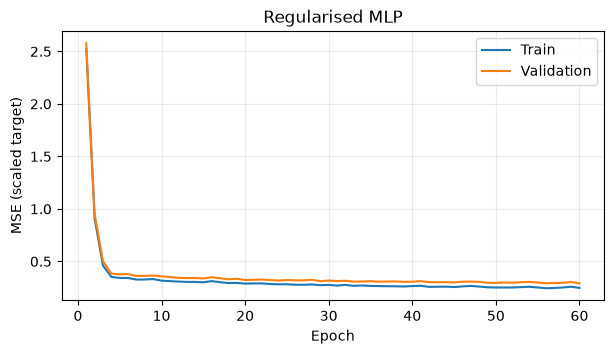

In [99]:
for name, h in all_histories.items():
    fig,ax=plt.subplots(figsize=(7,3.5))
    ax.plot(h.epoch,h.train_loss,label='Train')
    ax.plot(h.epoch,h.val_loss,label='Validation')
    ax.set(title=name, xlabel='Epoch',ylabel='MSE (scaled target)')
    ax.legend(); ax.grid(alpha=.25)
    plt.show()

## Step 10 — Identify potential overfitting with evidence

A model may **overfit** when **training loss continues to decrease but validation loss rises**. Early stopping may prevent long, obvious divergence. Inspect each graph and this table rather than claiming a model overfits without evidence.

`generalisation_gap` below is the final observed validation loss minus training loss, on the **scaled target** (lower is not automatically better). The best validation RMSE is still the main selection metric.

In [100]:
overfit_summary = []
for name, h in all_histories.items():
    best = h.loc[h['val_loss'].idxmin()]
    last = h.iloc[-1]
    following = h[h.epoch > best.epoch]
    # Simple signal only; always confirm visually using the loss curve.
    possible_overfit = (
        len(following) >= 3
        and following.train_loss.iloc[-1] < following.train_loss.iloc[0]
        and following.val_loss.iloc[-1] > following.val_loss.iloc[0]
    )
    overfit_summary.append({
        'model': name,
        'best_validation_epoch': int(best.epoch),
        'last_epoch': int(last.epoch),
        'last_train_mse': float(last.train_loss),
        'last_validation_mse': float(last.val_loss),
        'generalisation_gap': float(last.val_loss - last.train_loss),
        'possible_overfitting': bool(possible_overfit),
    })
overfit_df = pd.DataFrame(overfit_summary)
overfit_df.to_csv(ROOT / 'results' / 'overfitting_summary.csv', index=False)
display(overfit_df)
print('Interpretation: also open results/loss_curve_*.png and compare training vs validation trends.')

,model,best_validation_epoch,last_epoch,last_train_mse,last_validation_mse,generalisation_gap,possible_overfitting
0,Basic MLP,59,60,0.285185,0.323390,0.038205,False
1,Deep MLP,43,52,0.249221,0.299939,0.050717,False
2,Regularised MLP,60,60,0.247840,0.291657,0.043817,False


Interpretation: also open results/loss_curve_*.png and compare training vs validation trends.


In [101]:
best_model = fitted_models[champion]
best_model.eval()
with torch.no_grad():
    predicted_usd = best_model(torch.from_numpy(Xte)).numpy().reshape(-1) * 100_000
comparison = pd.DataFrame({
    'Actual house value ($)': y_test.to_numpy()[:10],
    'Predicted value ($)': predicted_usd[:10].round(2),
})
comparison['Absolute error ($)'] = (comparison.iloc[:,0] - comparison.iloc[:,1]).abs().round(2)
display(comparison)

,Actual house value ($),Predicted value ($),Absolute error ($)
0,100000.0,71155.242188,28844.76
1,118800.0,118336.703125,463.30
2,376100.0,344289.093750,31810.91
3,200000.0,153987.078125,46012.92
4,95200.0,162701.328125,67501.33
5,128500.0,109878.148438,18621.85
6,261300.0,223222.453125,38077.55
7,179400.0,189093.734375,9693.73
8,407000.0,428795.375000,21795.38
9,175000.0,198705.000000,23705.00


In [102]:
from pathlib import Path
print("Current folder:", Path.cwd())

Current folder: c:\Users\helen\project\ds-october-2026-week2\ds-october-2026\week2


In [103]:
df = pd.read_csv("housing.csv")

In [104]:
import mlflow
from mlflow.entities import ViewType
from mlflow.tracking import MlflowClient

mlflow.set_tracking_uri("sqlite:///mlflow.db")
client = MlflowClient()
housing_experiment = next(
    (experiment for experiment in client.search_experiments(view_type=ViewType.ALL)
     if experiment.name == "housing"),
    None,
)
if housing_experiment is not None and housing_experiment.lifecycle_stage == "deleted":
    client.restore_experiment(housing_experiment.experiment_id)

mlflow.set_experiment("housing")
print("MLflow experiment is ready!")

MLflow experiment is ready!


In [105]:
results, fitted_models, all_histories, run_ids = [], {}, {}, {}

for cfg in CONFIGS:
    torch.manual_seed(SEED)
    model = build_model(Xtr.shape[1], cfg)

    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.MSELoss()